### 1. Load and Explore the Dataset
Loading the dataset and checking its basic structure, columns, and data types to understand what preprocessing steps are needed.

In [6]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/content/updated_pollution_dataset.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (5000, 10)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Temperature                    5000 non-null   float64
 1   Humidity                       5000 non-null   float64
 2   PM2.5                          5000 non-null   float64
 3   PM10                           5000 non-null   float64
 4   NO2                            5000 non-null   float64
 5   SO2                            5000 non-null   float64
 6   CO                             5000 non-null   float64
 7   Proximity_to_Industrial_Areas  5000 non-null   float64
 8   Population_Density             5000 non-null   int64  
 9   Air Quality                    5000 non-null   object 
dtypes: float64(8), int64(1), object(1)
memory usage: 390.8+ KB

First 5 rows:


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


### 2. Preprocessing & Setup
Encode the target variable (`Air Quality`), separate our features, and split the data into training and testing sets using a stratified split to maintain class balance.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Separate features and target
X = df.drop(columns=['Air Quality'])
y_raw = df['Air Quality']

# Encode target labels to integers (required by XGBoost and standard for scikit-learn)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

# Save class names for later interpretation
class_names = label_encoder.classes_
print(f"Encoded Classes: {dict(enumerate(class_names))}")

# Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Encoded Classes: {0: 'Good', 1: 'Hazardous', 2: 'Moderate', 3: 'Poor'}
Training set shape: (4000, 9)
Testing set shape: (1000, 9)


### 3. Model Training & Comparison
Build pipelines for three baseline models: Logistic Regression, Random Forest, and XGBoost. Each pipeline includes standard scaling.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, balanced_accuracy_score

# Define model pipelines
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    'XGBoost': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42))
    ])
}

# Train and evaluate models
results = {}
print("--- Model Evaluation ---")
for name, pipeline in models.items():
    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluate
    acc = balanced_accuracy_score(y_test, y_pred)
    results[name] = {'Pipeline': pipeline, 'Balanced Accuracy': acc, 'Predictions': y_pred}

    print(f"{name} - Balanced Accuracy: {acc:.4f}")

# Select the best model (using XGBoost here as our primary robust tree model)
best_model_name = 'XGBoost'
best_pipeline = models[best_model_name]
print(f"\nSelected {best_model_name} for detailed evaluation.")

--- Model Evaluation ---
Logistic Regression - Balanced Accuracy: 0.8906
Random Forest - Balanced Accuracy: 0.9175


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [04:23:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost - Balanced Accuracy: 0.9204

Selected XGBoost for detailed evaluation.


### 4. Detailed Evaluation & Feature Importance
Model using a normalized confusion matrix and examine which features contribute the most to the predictions.


Classification Report for XGBoost:

              precision    recall  f1-score   support

        Good       1.00      1.00      1.00       400
   Hazardous       0.88      0.83      0.86       100
    Moderate       0.96      0.97      0.96       300
        Poor       0.88      0.89      0.88       200

    accuracy                           0.95      1000
   macro avg       0.93      0.92      0.92      1000
weighted avg       0.95      0.95      0.95      1000



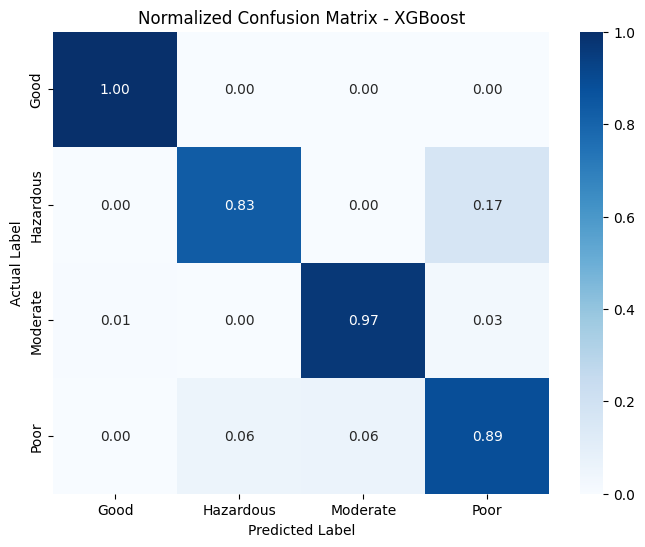

/tmp/ipykernel_4478/3969137348.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=X.columns, palette='viridis')


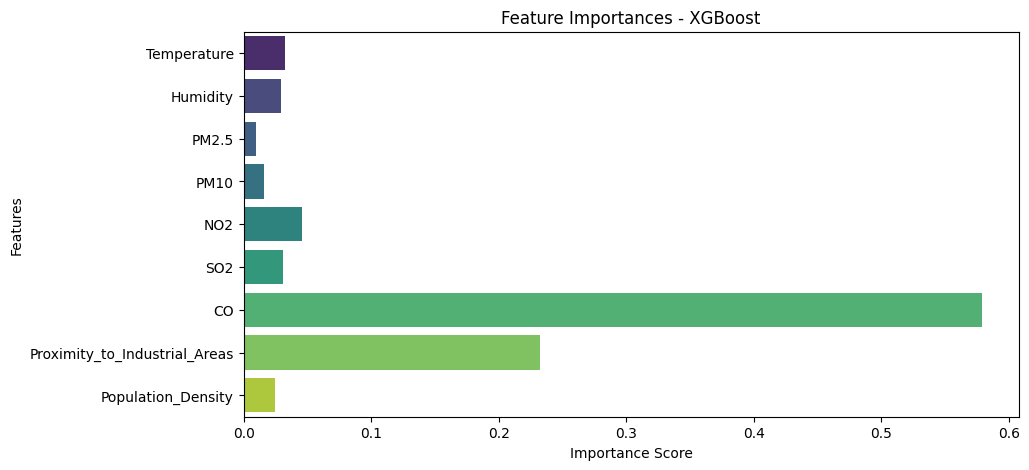

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Classification Report
y_pred_best = results[best_model_name]['Predictions']
print(f"\nClassification Report for {best_model_name}:\n")
print(classification_report(y_test, y_pred_best, target_names=class_names))

# 2. Normalized Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best, normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Normalized Confusion Matrix - {best_model_name}')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# 3. Feature Importance (Extracting from the tree model inside the pipeline)
# XGBoost is the second step in the pipeline: best_pipeline.named_steps['classifier']
classifier = best_pipeline.named_steps['classifier']
importances = classifier.feature_importances_

# Plot Feature Importances
plt.figure(figsize=(10, 5))
sns.barplot(x=importances, y=X.columns, palette='viridis')
plt.title(f'Feature Importances - {best_model_name}')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

### 5. Reusable Inference Function
simulates how a backend application (like your FLORES system) would receive raw JSON/dictionary data, process it through the pipeline, and return a prediction with confidence scores.

In [10]:
def predict_air_quality(input_dict, pipeline, encoder):
    """
    Predicts Air Quality given a dictionary of raw sensor readings.

    Args:
        input_dict (dict): Dictionary with keys matching feature names.
        pipeline (sklearn.pipeline.Pipeline): Trained model pipeline.
        encoder (sklearn.preprocessing.LabelEncoder): Fitted label encoder.

    Returns:
        dict: Contains predicted class, confidence, and probabilities for all classes.
    """
    # Convert input to DataFrame (required to match training feature names)
    input_df = pd.DataFrame([input_dict])

    # Get probabilities
    probs = pipeline.predict_proba(input_df)[0]

    # Get highest probability class
    pred_idx = probs.argmax()
    pred_class = encoder.inverse_transform([pred_idx])[0]
    confidence = probs[pred_idx]

    # Map probabilities to class names for the API response
    prob_dict = {encoder.inverse_transform([i])[0]: float(prob)
                 for i, prob in enumerate(probs)}

    return {
        'predicted_category': pred_class,
        'confidence_score': float(confidence),
        'all_probabilities': prob_dict
    }

# ---- Inference Test ----
# Let's simulate a reading from the sensors
sample_reading = {
    'Temperature': 28.5,
    'Humidity': 60.2,
    'PM2.5': 12.4,
    'PM10': 25.1,
    'NO2': 20.5,
    'SO2': 8.3,
    'CO': 1.2,
    'Proximity_to_Industrial_Areas': 5.5,
    'Population_Density': 450
}

# Run the inference function
result = predict_air_quality(sample_reading, best_pipeline, label_encoder)

print("\n--- Inference Result ---")
for key, value in result.items():
    if isinstance(value, dict):
        print(f"{key}:")
        for k, v in value.items():
            print(f"  {k}: {v:.4f}")
    else:
        print(f"{key}: {value}")


--- Inference Result ---
predicted_category: Moderate
confidence_score: 0.9995660185813904
all_probabilities:
  Good: 0.0004
  Hazardous: 0.0000
  Moderate: 0.9996
  Poor: 0.0000
